# Beja --> distrito 16

In [56]:
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
import pickle 
from tqdm import tqdm
import numpy as np
from sklearn.metrics import mean_squared_error

df_16 = pd.read_csv('df_16_d.csv')
df_16_y = pd.read_csv('df_16_y_d.csv')

df_16['ID'] = [i for i in range(len(df_16))]
df_16_y['ID'] = [i for i in range(len(df_16_y))]

# Coluna = 'Unnamed: 0' --> corresponde aos id reais!! <-- IMP

In [57]:
df_16

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
0,8,True,0.214286,Garden,0.12,0.10,True,0.142857,0.675672,-0.068974,0
1,9,2005,0.357143,True,0.22,0.20,d,0.571429,0.671889,-0.077851,1
2,11,True,0.214286,Swimming pool,0.16,0.14,b,0.571429,0.670349,-0.076226,2
3,12,True,0.357143,True,0.18,0.18,f,0.142857,0.679926,-0.073440,3
4,17,True,0.357143,Garden,0.12,0.12,g,0.571429,0.675704,-0.068982,4
...,...,...,...,...,...,...,...,...,...,...,...
1054,4470,1991,0.285714,True,0.20,0.20,d,1.000000,0.671703,-0.075243,1054
1055,4473,True,0.285714,True,0.12,0.12,True,0.142857,0.670798,-0.076555,1055
1056,4474,1985,0.357143,Garden,0.26,0.24,d,1.000000,0.675967,-0.070768,1056
1057,4479,True,0.214286,True,0.08,0.08,d,0.142857,0.677297,-0.073182,1057


# Pre-processamento 

### Colunas: 
- built_in
- amenities
- energetic_efficiency

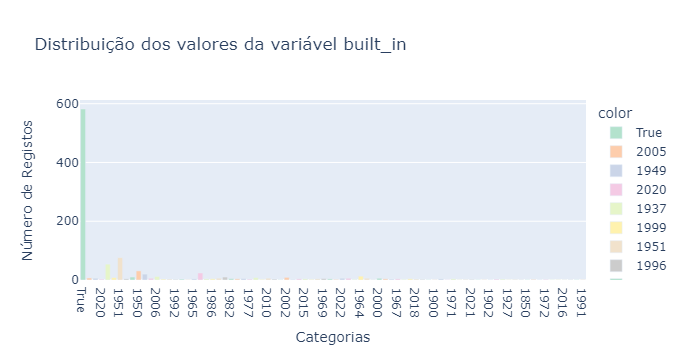

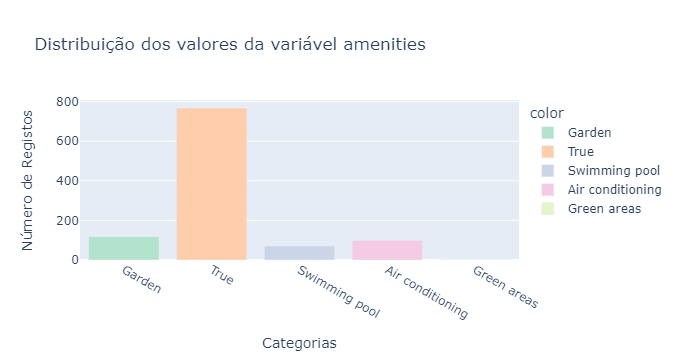

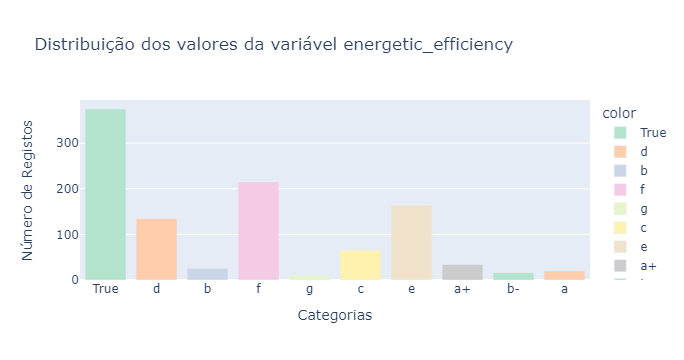

In [58]:
# Variação dos dados 
import plotly.express as px
col = ['built_in', 'amenities','energetic_efficiency']

for nome in col: 
    output = []
    names = df_16[nome].unique()
    for i in df_16[nome].unique():
        bt2 = df_16[nome].value_counts()[i]
        output.append(bt2)
    fig = px.bar(df_16, x=names, y=output, color = names ,color_discrete_sequence= px.colors.qualitative.Pastel2, title= f'Distribuição dos valores da variável {nome}')
    fig.update_xaxes(title_text='Categorias')
    fig.update_yaxes(title_text='Número de Registos')
    fig.show()

### --> Eficiência Energética

In [59]:
from sklearn.neighbors import KNeighborsClassifier
# Cluster para ver as casas mais parecidas, para depois asoociar um valor aos imóveis que não têm eficiencia energética

# Obter ID onde energetic_efficiency == 'True' e ou != 'True'
ids_true16 = list(df_16.loc[df_16['energetic_efficiency'] == 'True', 'ID']) # O que vão ser previstos 
ids_outros16 = list(df_16.loc[df_16['energetic_efficiency'] != 'True', 'ID'])


# Dados 
teste16 = df_16.loc[ids_true16,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
#teste_y16 = df_16.loc[ids_true16,['energetic_efficiency']]
treino16 = df_16.loc[ids_outros16,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
treino_y16 = df_16.loc[ids_outros16,['energetic_efficiency']]

# Comparação --> X_train_16[['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
def KNN(k, teste, treino, treino_y):
    knn =  KNeighborsClassifier(n_neighbors=k)
    knn.fit(treino, treino_y)
    y_pred = knn.predict(teste)
    return y_pred
l_ee16 = KNN(3, teste16, treino16, treino_y16)

# Substituir os True

def sub_ee(ids_true, l_ee, df, col):
    for i in range(len(ids_true)): 
        df.loc[df['ID'] == ids_true[i], col] = l_ee[i]
    return df
df_16 = sub_ee(ids_true16, l_ee16, df_16, 'energetic_efficiency')


ee16 = df_16.loc[:, ['energetic_efficiency']]

def substituir_energetic_efficiency(X):
    X = X.replace('a+', 1)
    X = X.replace('a', 2)
    X = X.replace('b', 3)
    X = X.replace('b-', 4)
    X = X.replace('c', 5)
    X = X.replace('d', 6)
    X = X.replace('e', 7)
    X = X.replace('f', 8)
    X = X.replace('g', 9)
    
    return X
ee16 = substituir_energetic_efficiency(ee16)

# normalizar valores 
def norm_ee(df1): 
    
    df1['energetic_efficiency'] = df1['energetic_efficiency'] /df1['energetic_efficiency'].abs().max()
    return df1
ee16 = norm_ee(ee16)

df_16['energetic_efficiency'] = ee16

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neighbors\_classification.py:233: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



### --> Amenities

In [60]:
aa16 = df_16.loc[:, ['amenities']]

def substituir_amenities(X):
    X = X.replace('True ', 1)
    X = X.replace('Air conditioning ', 2)
    X = X.replace('Garden ', 3)
    X = X.replace('Green areas ', 3)
    X = X.replace('Swimming pool ', 4)
    
    return X
aa16 = substituir_amenities(aa16)

# normalizar valores 
def norm_amenities(df1): 
    
    df1['amenities'] = df1['amenities'] /11
    return df1
aa16 = norm_amenities(aa16)

df_16['amenities'] = aa16

### --> built_in

In [61]:
id_true16 = list(df_16.loc[df_16['built_in'] == 'True', 'ID'])
id_outros16 = list(df_16.loc[df_16['built_in'] != 'True', 'ID'])

# Obter anos que têm menos de 2 samples 

def menos_2(df, nome): 
    l = []
    for i in df[nome].unique():
        bt2 = df[nome].value_counts()[i]
        if bt2 < 3: 
            l.append(i) 
    return l
lista_data16 = menos_2(df_16, 'built_in')

def replicação_menos2(df, lista_data, id_outros):
    for ano in lista_data: 
        id_ano = list(df.loc[df['built_in'] == ano, 'ID'])
        for i in range(len(id_ano)):
            id_outros.append(id_ano[i])
            id_outros.append(id_ano[i])
    return id_outros

id_outros16 = replicação_menos2(df_16, lista_data16, id_outros16)

# Dados 
# criar dataset com price

d_b16 =  df_16.loc[:,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
d_b_216 = df_16_y.loc[:,['Price_norm']]
#d_b = pd.concat([d_b_1, d_b_2])
d_b16 = d_b16.join(d_b_216)


teste_b16 = d_b16.loc[id_true16,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm','Price_norm']]
#teste_y16 = df_16.loc[ids_true16,['built_in']]
treino_b16 = d_b16.loc[id_outros16,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm','Price_norm']]
treino_b_y16 = df_16.loc[id_outros16,['built_in']]

# KNN
l_b_i16 = KNN(3, teste_b16, treino_b16, treino_b_y16)

# Substituir
df_16 = sub_ee(id_true16, l_b_i16, df_16, 'built_in')

b_i16 = df_16.loc[:, ['built_in']]
b_i16['built_in'] = b_i16['built_in'].astype(int)

# normalizar valores 
def norm_b_i(df1): 
    
    df1['built_in'] = df1['built_in'] /2024
    return df1
b_i16 = norm_b_i(b_i16)

df_16['built_in'] = b_i16

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neighbors\_classification.py:233: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



In [62]:
df_16

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
0,8,0.964427,0.214286,0.272727,0.12,0.10,0.222222,0.142857,0.675672,-0.068974,0
1,9,0.990613,0.357143,0.090909,0.22,0.20,0.666667,0.571429,0.671889,-0.077851,1
2,11,0.957016,0.214286,0.363636,0.16,0.14,0.333333,0.571429,0.670349,-0.076226,2
3,12,0.957016,0.357143,0.090909,0.18,0.18,0.888889,0.142857,0.679926,-0.073440,3
4,17,0.963439,0.357143,0.272727,0.12,0.12,1.000000,0.571429,0.675704,-0.068982,4
...,...,...,...,...,...,...,...,...,...,...,...
1054,4470,0.983696,0.285714,0.090909,0.20,0.20,0.666667,1.000000,0.671703,-0.075243,1054
1055,4473,0.963439,0.285714,0.090909,0.12,0.12,0.666667,0.142857,0.670798,-0.076555,1055
1056,4474,0.980731,0.357143,0.272727,0.26,0.24,0.666667,1.000000,0.675967,-0.070768,1056
1057,4479,0.963933,0.214286,0.090909,0.08,0.08,0.666667,0.142857,0.677297,-0.073182,1057


# Modelo

In [63]:

# Dividir em treino e teste

X_train_16, X_test_16, y_train_16, y_test_16 = train_test_split(df_16, df_16_y, test_size=0.15, random_state=42)
X_train_16

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
66,262,0.963439,0.214286,0.090909,0.12,0.12,0.888889,0.428571,0.674940,-0.073481,66
843,3557,0.957016,0.428571,0.090909,0.32,0.28,0.666667,0.142857,0.670798,-0.076555,843
67,264,0.992095,0.928571,0.090909,0.52,0.02,0.555556,0.571429,0.678613,-0.074209,67
849,3573,0.957016,0.214286,0.090909,0.14,0.08,0.888889,1.000000,0.670838,-0.078217,849
12,62,0.963933,0.285714,0.363636,0.34,0.34,0.111111,0.428571,0.676051,-0.070763,12
...,...,...,...,...,...,...,...,...,...,...,...
330,1397,0.957016,0.428571,0.090909,0.20,0.12,0.666667,0.142857,0.678043,-0.075555,330
466,2045,0.982708,0.285714,0.090909,0.14,0.14,0.666667,0.285714,0.677338,-0.073580,466
121,474,0.975296,0.285714,0.090909,0.52,0.52,0.111111,0.571429,0.670838,-0.078217,121
1044,4444,0.957016,0.285714,0.090909,0.16,0.16,0.888889,0.142857,0.675682,-0.068970,1044


In [64]:
X_train16 = X_train_16[['tipology', 'amenities', 'built_in','energetic_efficiency', 'house_type']]
X_test16 = X_test_16[[ 'tipology', 'amenities', 'built_in', 'energetic_efficiency', 'house_type']]
y_train16 = y_train_16[['Price_norm']]
y_test16 = y_test_16[['Price_norm']]

# MLPRegressor

In [74]:
# Melhor modelo GridSearchCV collab

"""
regr = MLPRegressor(hidden_layer_sizes=(150,), activation='relu',  solver='lbfgs',alpha=0.005, learning_rate= 'adaptive', learning_rate_init = 0.1,  tol = 0.001, max_iter=1000).fit(X_train16, y_train16)
y_pred = regr.predict(X_test16)
y_pred = [abs(x) for x in y_pred]
#print(y_pred)
print(mean_squared_error(y_pred,y_test16))
print(regr.score(X_test16, y_test16))

### Guardar o modelo

import pickle

with open('modelo_dist16.pkl', 'wb') as file:
    pickle.dump(regr, file)
"""

0.005900410752818187
0.2896214772865702


C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1625: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().



In [75]:
# abrir modelo

with open('modelo_dist16.pkl', 'rb') as f:
    MLR = pickle.load(f)
MLR

MLPRegressor(alpha=0.005, hidden_layer_sizes=(150,), learning_rate='adaptive',
             learning_rate_init=0.1, max_iter=1000, solver='lbfgs', tol=0.001)

In [76]:
y_prev = MLR.predict(X_test16)

# OUTPUT E VIS

In [77]:
y_test16['prev_norm'] = y_prev

C:\Users\User\AppData\Local\Temp\ipykernel_23004\3129200308.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [78]:
# Desnormalizar valores e Criar 'Price_prev'
def desnormalizar(valor):
    maximoout= 15000000 # depois mudar este valor, para o verdadeiro máximo
    return np.round(valor * maximoout,0)

def lista_des(lista): 
    n_l = []
    for i in lista: 
        n_l.append(desnormalizar(i))
    return n_l

y_test16['Price_prev'] = lista_des(y_prev)

def df_criar_id(y_test, df_13_y):
    y_test['Price_Real'] =[0] * len(y_test)
    for i in y_test.index:
        y_test['Price_Real'][i] = df_13_y['Price_Real'].iloc[i]
    return y_test
y_test16 = df_criar_id(y_test16, df_16_y)

C:\Users\User\AppData\Local\Temp\ipykernel_23004\1448124976.py:12: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_23004\1448124976.py:17: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_23004\1448124976.py:17: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_

In [79]:
# Crirar intervalo de preço

def intervalo_preco(y):
    l =  []
    for i in y['Price_prev']: 
        p_int = [i-(i*0.03), i+(i*0.03)]
        l.append(p_int)
    y['Price_Prev_Int'] = l
    return y

y_test16 =  intervalo_preco(y_test16)

In [80]:
y_test16

,Price_norm,prev_norm,Price_prev,Price_Real,Price_Prev_Int
576,0.493333,0.132525,1987879.0,7400000,"[1928242.63, 2047515.37]"
312,0.004700,-0.010567,-158510.0,70500,"[-153754.7, -163265.3]"
70,0.005300,-0.003849,-57742.0,79500,"[-56009.74, -59474.26]"
682,0.008667,0.050997,764953.0,130000,"[742004.41, 787901.59]"
896,0.003733,-0.004064,-60957.0,56000,"[-59128.29, -62785.71]"
...,...,...,...,...,...
465,0.007067,0.006902,103523.0,106000,"[100417.31, 106628.69]"
961,0.031200,0.097125,1456873.0,468000,"[1413166.81, 1500579.19]"
558,0.003200,0.008171,122561.0,48000,"[118884.17, 126237.83]"
333,0.041667,0.080488,1207314.0,625000,"[1171094.58, 1243533.42]"


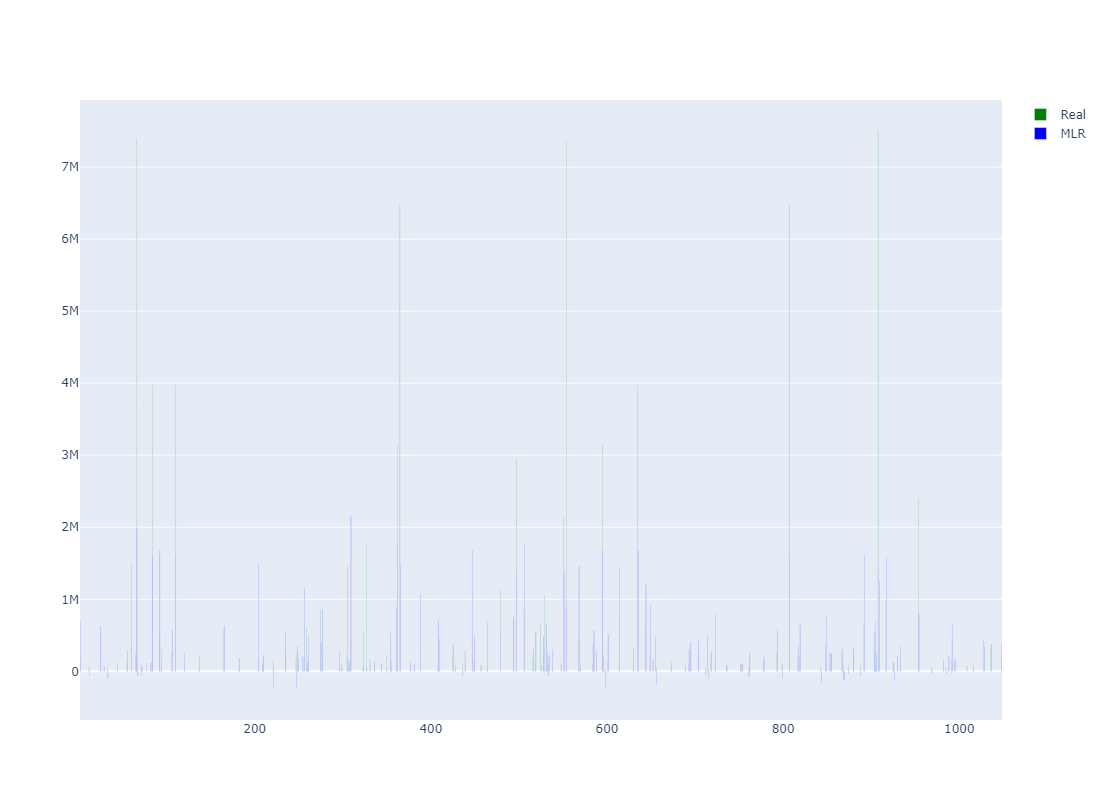

In [81]:
import plotly.graph_objects as go

# Grafico preço real e valor previsto
fig = go.Figure(
    data=[
        go.Bar(x=X_train_16.ID, y=y_test16.Price_Real, name="Real", marker_color='green'),
        go.Bar(x=X_train_16.ID, y=y_test16.Price_prev, name="MLR",  marker_color='blue'),
    ],
)
fig.update_layout(
    autosize=False,
    width=1000,
    height=800)

fig.show()